# Кластеризация ЕГЭ (8.5 если сделаны все задачи)

Рядом лежат экселевские таблицы с координатами точек. В 3 и 4 задаче используется манхетеское расстояние. В остальных Евклидово.

* Постройте Распределение точек
* Кластеризуйте руками
* Постройте Распределение точек, отметьте принадлежность кластеров цветами
* Найдите среди в каждом кластере точку расстояние от которой до всех остальных минимально
* Выведите усреднение центров всех кластеров * 1000

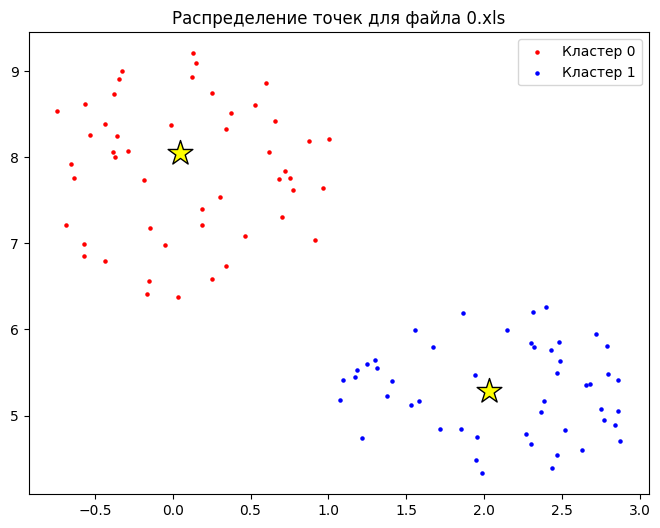

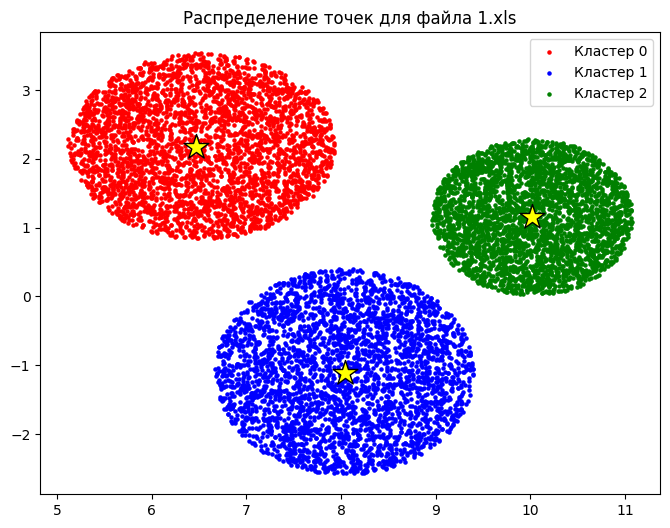

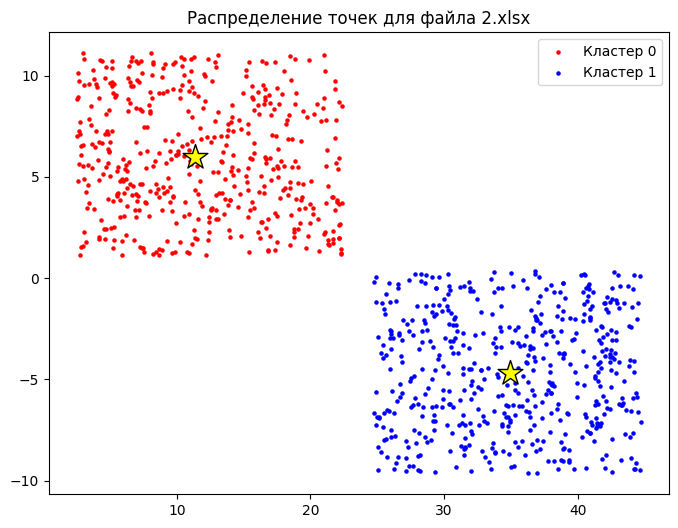

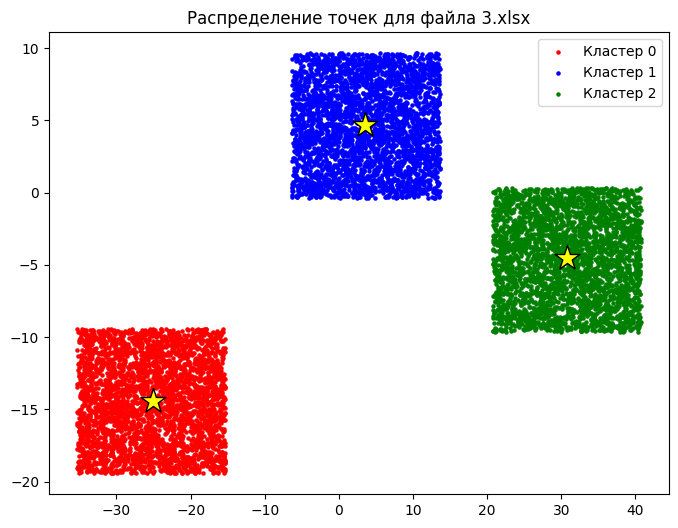

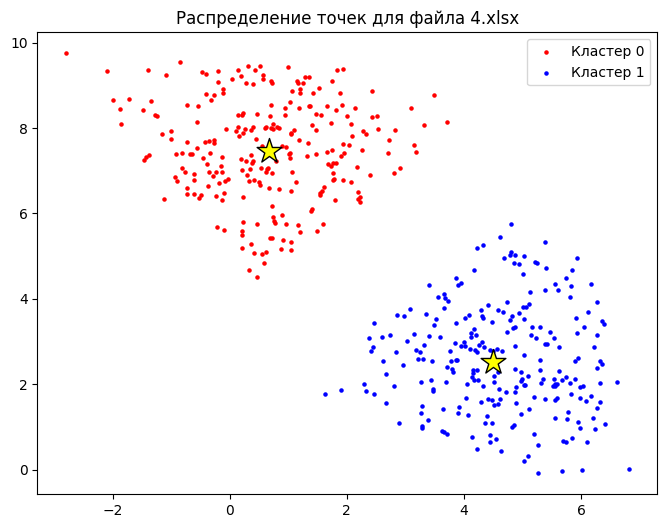

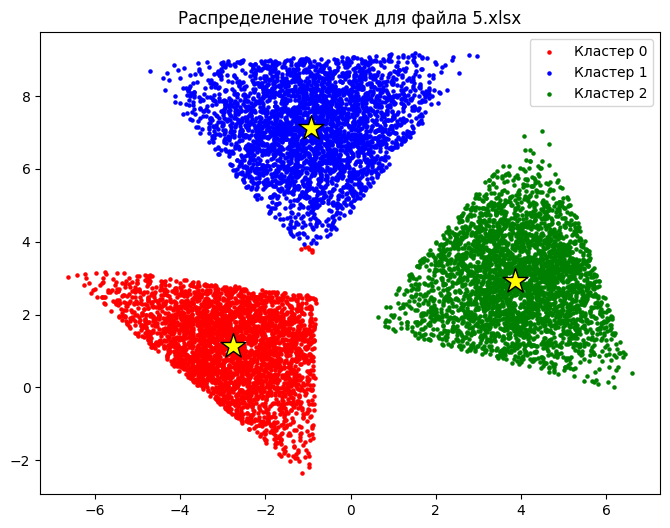


Готово! Усредненные центры * 1000:
0.xls: X = 1041.01, Y = 6671.17
1.xls: X = 8177.53, Y = 738.42
2.xlsx: X = 23130.22, Y = 635.34
3.xlsx: X = 3078.89, Y = -4758.95
4.xlsx: X = 2588.54, Y = 4996.57
5.xlsx: X = 61.65, Y = 3723.36


In [30]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import math

INF = 1e9

def plot_clasters(X, labels, k, filename, centrs):
    colors = ['red', 'blue', 'green']
    plt.figure(figsize=(8, 6))
    for cluster_id in range(k):
        x_coords = []
        y_coords = []

        for i in range(len(X)):
            if labels[i] == cluster_id:
                x_coords.append(X[i][0])
                y_coords.append(X[i][1])

        plt.scatter(x_coords, y_coords, color=colors[cluster_id], s=5, label=f'Кластер {cluster_id}')

    for best_centr in centrs:
        plt.scatter(best_centr[0], best_centr[1],
                    color='yellow', marker='*', s=350, edgecolors='black', zorder=5)

    plt.title(f"Распределение точек для файла {filename}")
    plt.legend()
    plt.show()


def distance(p1, p2, metric):
    if metric == 'euclidean':
        return math.sqrt((p1[0] - p2[0]) ** 2 + (p1[1] - p2[1]) ** 2)
    else:
        return abs(p1[0] - p2[0]) + abs(p1[1] - p2[1])


def kmean(X, k, metric='euclidean'):
    centroids = []

    sorted_X = sorted(X, key=lambda p: p[0])
    step = len(sorted_X) // k
    for i in range(k):
        index = i * step + (step // 2)
        centroids.append([sorted_X[index][0], sorted_X[index][1]])

    labels = np.zeros(len(X))

    for step_num in range(20):
        for i in range(len(X)):
            point = X[i]
            min_dist = INF
            best = 0

            for c in range(k):
                dist = distance(point, centroids[c], metric)
                if dist < min_dist:
                    min_dist = dist
                    best = c

            labels[i] = best

        for c in range(k):
            sum_x = 0
            sum_y = 0
            cnt = 0

            for i in range(len(X)):
                if labels[i] == c:
                    sum_x += X[i][0]
                    sum_y += X[i][1]
                    cnt += 1

            if cnt > 0:
                centroids[c][0] = sum_x / cnt
                centroids[c][1] = sum_y / cnt

    return labels


files = ['0.xls', '1.xls', '2.xlsx', '3.xlsx', '4.xlsx', '5.xlsx']
k_values = [2, 3, 2, 3, 2, 3]

metrics = ['euclidean', 'euclidean', 'euclidean', 'manhet', 'manhet', 'euclidean']
results = []

for f, k, metric in zip(files, k_values, metrics):
    if f in ['2.xlsx', '3.xlsx']:
        df = pd.read_excel(f, header=None, names=['X', 'Y'])
    else:
        df = pd.read_excel(f)

    X = df[['X', 'Y']].values
    labels = kmean(X, k, metric=metric)

    centrs = []
    for cluster_id in range(k):
        cluster_points = []
        for i in range(len(X)):
            if labels[i] == cluster_id:
                cluster_points.append(X[i])
        cluster_points = np.array(cluster_points)

        distmn = INF
        best_centr = None

        for i in range(len(cluster_points)):
            point = cluster_points[i]

            if metric == 'euclidean':
                dists = np.sqrt((cluster_points[:, 0] - point[0]) ** 2 + (cluster_points[:, 1] - point[1]) ** 2)
            else:
                dists = np.abs(cluster_points[:, 0] - point[0]) + np.abs(cluster_points[:, 1] - point[1])

            total_dist = np.sum(dists)

            if total_dist < distmn:
                distmn = total_dist
                best_centr = point

        centrs.append(best_centr)

    centrs = np.array(centrs)
    avg_center = np.mean(centrs, axis=0) * 1000
    results.append((f, avg_center))
    plot_clasters(X, labels, k, f, centrs)

print("\nГотово! Усредненные центры * 1000:")
for f, avg_center in results:
    print(f"{f}: X = {avg_center[0]:.2f}, Y = {avg_center[1]:.2f}")

# Кластеризация (0.75 за каждый алгоритм на всех данных)

На предложенных распределениях данных проверьте предложенные алгоритмы. Постройте графики кластеризации для каждой пары алгоритм-данные, разные кластеры покрасьте разным цветом. Воспользуйтесь sklearn реализациями. Параметры кластеризации для разных алгоритмов подберите такие, чтобы алгоритмы можно было сравнивать (по возможности одинаковое количество кластеров и т.д.)

In [2]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from sklearn import cluster, datasets, mixture
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler
from itertools import cycle, islice

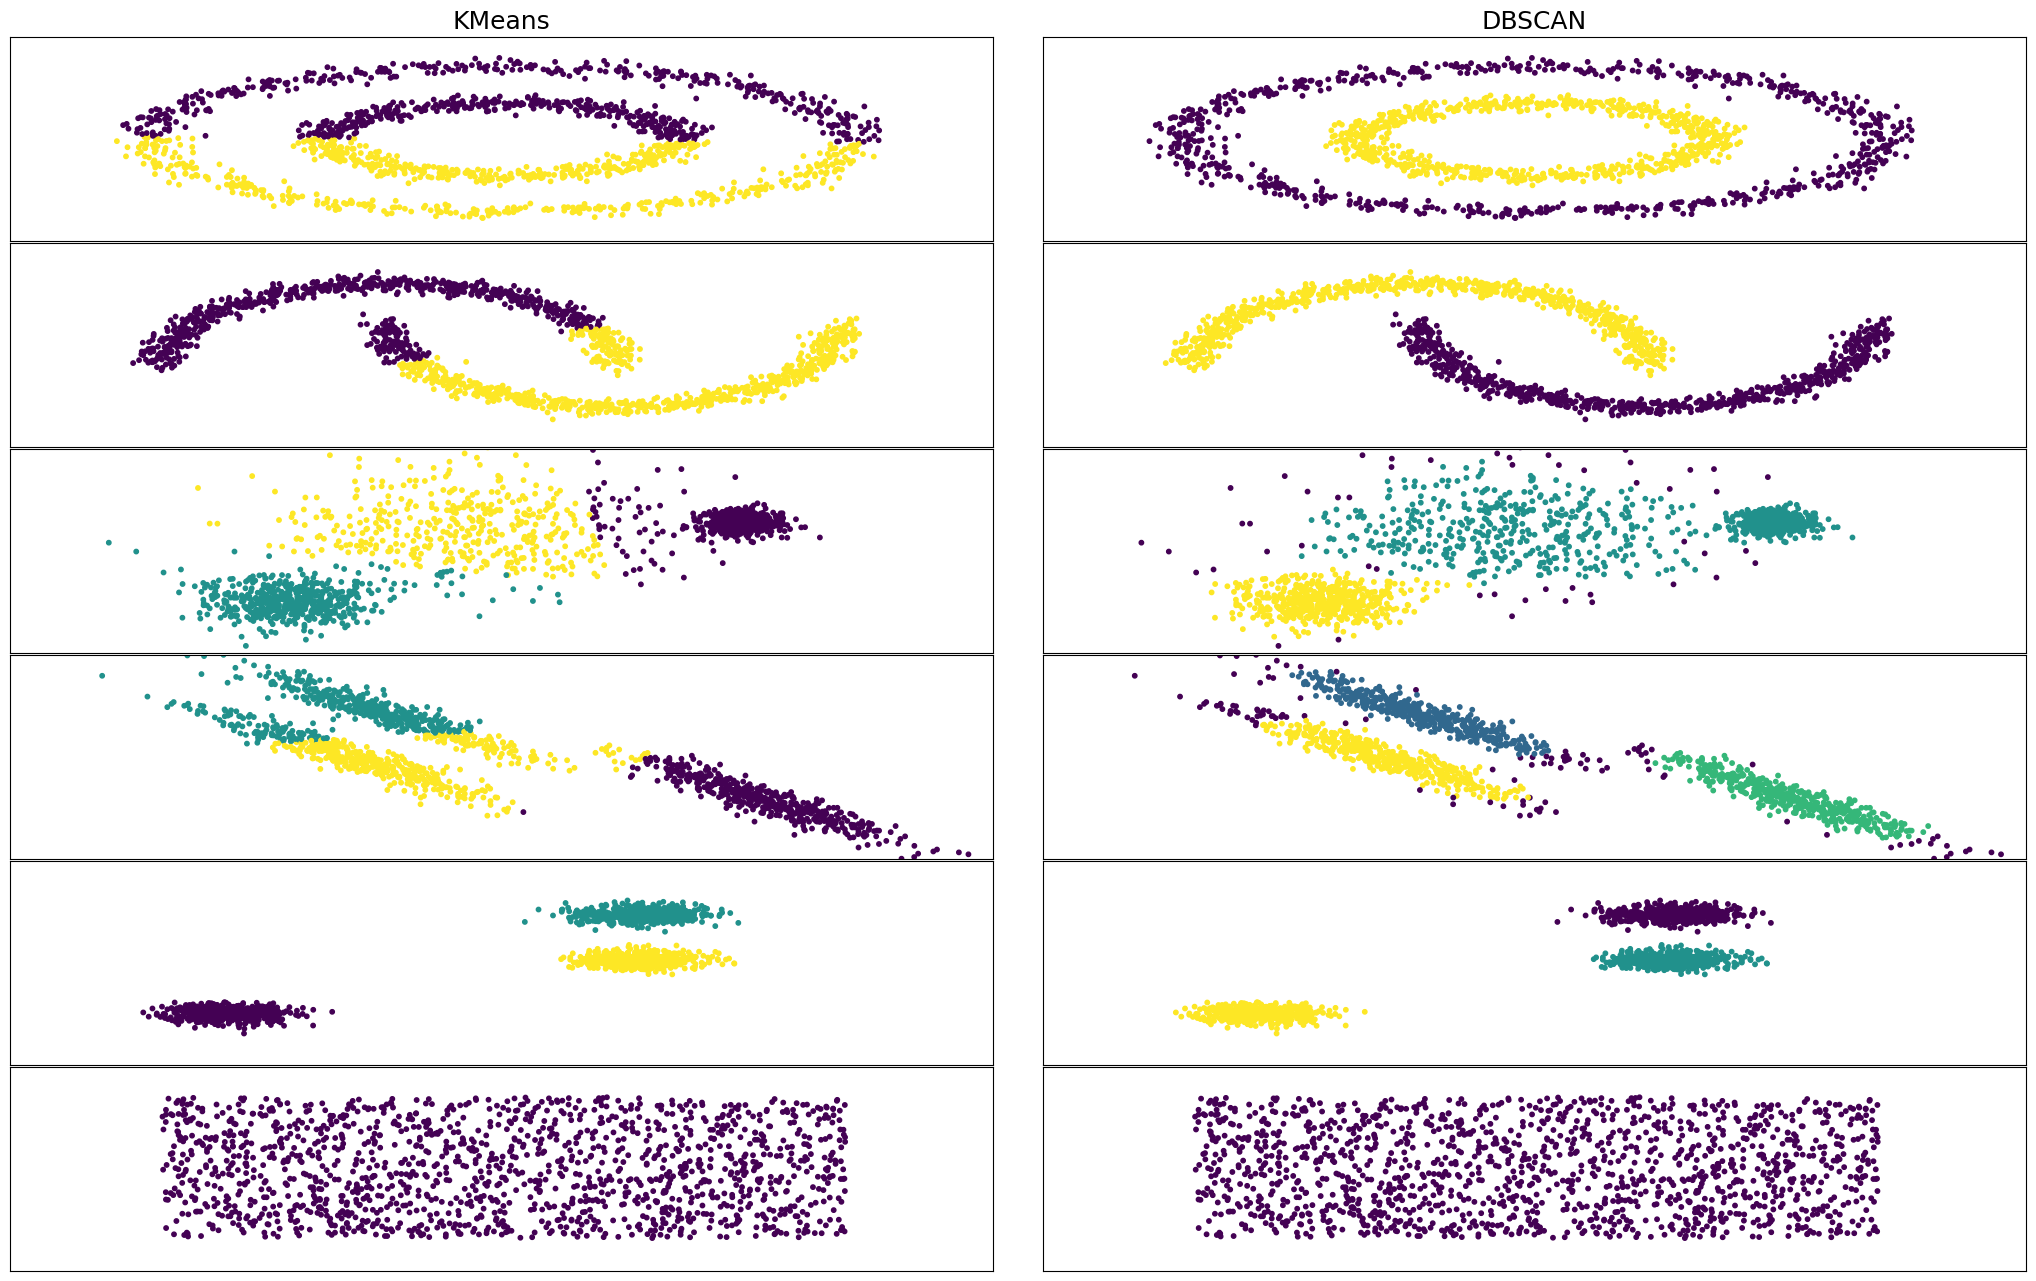

In [18]:
np.random.seed(0)

# ============
# Generate datasets. We choose the size big enough to see the scalability
# of the algorithms, but not too big to avoid too long running times
# ============
n_samples = 1500
noisy_circles = datasets.make_circles(n_samples=n_samples, factor=0.5, noise=0.05)
noisy_moons = datasets.make_moons(n_samples=n_samples, noise=0.05)
blobs = datasets.make_blobs(n_samples=n_samples, random_state=8)
no_structure = np.random.rand(n_samples, 2), None

# Anisotropicly distributed data
random_state = 170
X, y = datasets.make_blobs(n_samples=n_samples, random_state=random_state)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)
aniso = (X_aniso, y)

# blobs with varied variances
varied = datasets.make_blobs(
    n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=random_state
)

# ============
# Set up cluster parameters
# ============
plt.figure(figsize=(9 * 2 + 3, 13))
plt.subplots_adjust(
    left=0.02, right=0.98, bottom=0.001, top=0.95, wspace=0.05, hspace=0.01
)

plot_num = 1

default_base = {
    "quantile": 0.3,
    "eps": 0.3,
    "damping": 0.9,
    "preference": -200,
    "n_neighbors": 10,
    "n_clusters": 3,
    "min_samples": 20,
    "xi": 0.05,
    "min_cluster_size": 0.1,
}

datasets_list = [
    (
        noisy_circles,
        {
            "damping": 0.77,
            "preference": -240,
            "quantile": 0.2,
            "n_clusters": 2,
            "min_samples": 20,
            "xi": 0.25,
        },
    ),
    (noisy_moons, {"damping": 0.75, "preference": -220, "n_clusters": 2}),
    (
        varied,
        {
            "eps": 0.18,
            "n_neighbors": 2,
            "min_samples": 5,
            "xi": 0.035,
            "min_cluster_size": 0.2,
        },
    ),
    (
        aniso,
        {
            "eps": 0.15,
            "n_neighbors": 2,
            "min_samples": 20,
            "xi": 0.1,
            "min_cluster_size": 0.2,

        },
    ),
    (blobs, {}),
    (no_structure, {"n_clusters": 1,}),
]

for i_dataset, (dataset, algo_params) in enumerate(datasets_list):
    # update parameters with dataset-specific values
    params = default_base.copy()
    params.update(algo_params)

    X, y = dataset

    # normalize dataset for easier parameter selection
    X = StandardScaler().fit_transform(X)

    # estimate bandwidth for mean shift
    bandwidth = cluster.estimate_bandwidth(X, quantile=params["quantile"])

    # connectivity matrix for structured Ward
    connectivity = kneighbors_graph(
        X, n_neighbors=params["n_neighbors"], include_self=False
    )
    # make connectivity symmetriс
    connectivity = 0.5 * (connectivity + connectivity.T)


    kmeans = cluster.KMeans(n_clusters=params["n_clusters"], n_init="auto")
    dbscan = cluster.DBSCAN(eps=params["eps"], min_samples=params["min_samples"])

    for name, algorithm in [("KMeans", kmeans), ("DBSCAN", dbscan)]:
        algorithm.fit(X)
        labels = algorithm.labels_

        plt.subplot(len(datasets_list), 2, plot_num)

        if i_dataset == 0:
            plt.title(name, size=18)

        plt.scatter(X[:, 0], X[:, 1], c=labels, s=10)


        #const size
        plt.xlim(-2.5, 2.5)
        plt.ylim(-2.5, 2.5)
        #oxyz
        plt.xticks([])
        plt.yticks([])

        plot_num += 1

plt.show()